# Credit default risk and expected loss

**Tanner Allred** · Houston

Behavioral probability of default for a retail credit-card book, plus the expected-loss and cutoff view a portfolio analyst would take into a committee.

The accounts already have six statement months (UCI *Default of Credit Card Clients*, Taiwan, April–September 2005). The label is default the following month. Amounts are New Taiwan dollars. The fitting code lives in `src/credit_risk` and is covered by `tests/`. This notebook is the walkthrough of one seeded run.

## 1. Run the protocol

Stratified 80/20 split, seed 42. Five-fold cross-validation on the training set. A class-weighted variant is kept only if it lifts training AUC by at least 0.005. Gradient boosting becomes the decision model only if it beats the scorecard by that same margin. Isotonic calibration is fit on out-of-fold scores. Sex and marital status are excluded. LGD of 75% and a 10% conversion factor on undrawn limit are assumptions, because the file has no recoveries.

In [1]:
from pathlib import Path
import sys

import pandas as pd
from IPython.display import Image, display

root = Path.cwd().resolve()
if not (root / "src" / "credit_risk").exists():
    root = root.parent
sys.path.insert(0, str(root / "src"))

from credit_risk.pipeline import run_all

pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 120)

result = run_all(save=True, verbose=True)
metrics = result["metrics"]
print("Champion:", metrics["champion"])
print("Versions:", metrics["versions"])

Loaded 30,000 rows from the UCI workbook


Clean book: 30,000 accounts, default rate 22.12% (6,636 defaults)


Split: train 24,000 / holdout 6,000, seed 42


Writing exploratory charts from the training sample


Cross-validating the scorecard (5 folds, unweighted and balanced)


  scorecard CV AUC 0.758 (unweighted)


... (3 outputs left out)

Holdout AUC  repayment 0.676  scorecard 0.740  boosting 0.782


Computing SHAP values for the gradient boosting model


Wrote figures, tables, and metrics.json


Champion: gradient_boosting
Versions: {'python': '3.12.3', 'numpy': '2.5.5', 'pandas': '3.1.1', 'scikit-learn': '1.9.1', 'xgboost': '3.4.1', 'shap': '0.54.1', 'matplotlib': '3.11.2'}


## 2. Book and data quality

30,000 accounts, no dropped rows. Undocumented education and marriage codes are folded into "other" and counted below. `PAY_0` in the source file is the latest statement; it is renamed `pay_1` so it lines up with `bill_amt1`.

In [2]:
cleaning = pd.Series(metrics["dataset"]["cleaning"])
summary = pd.Series(
    {
        "accounts": metrics["dataset"]["rows"],
        "defaults": metrics["dataset"]["defaults"],
        "default_rate": metrics["dataset"]["default_rate"],
        "train_rows": metrics["dataset"]["train_rows"],
        "holdout_rows": metrics["dataset"]["test_rows"],
        "holdout_default_rate": metrics["dataset"]["test_default_rate"],
    }
)
display(summary.to_frame("value"))
display(cleaning.to_frame("cleaning"))
display(result["sql"]["portfolio_snapshot"])

,value
accounts,"30,000.0000"
defaults,"6,636.0000"
default_rate,0.2212
train_rows,"24,000.0000"
holdout_rows,"6,000.0000"
holdout_default_rate,0.2212


,cleaning
rows_in,"30,000.0000"
education_undocumented,345.0000
marriage_undocumented,54.0000
rows_with_any_null_in_required,0.0000
nonpositive_limit,0.0000
duplicate_ids,0.0000
rows_out,"30,000.0000"
default_rate,0.2212
defaults,"6,636.0000"


,accounts,defaults,default_rate,avg_limit,avg_positive_balance,avg_utilization
0,30000,6636,0.2212,"167,484.0000","56,105.0000",0.4238


## 3. What separates defaults

Recent repayment status is the steep relationship. Utilization slopes the same way and much more gently. Defaults also sit on smaller limits (full-book median NT$90,000 versus NT$150,000). Charts below are the training sample, so the pictures are not drawn with the holdout.

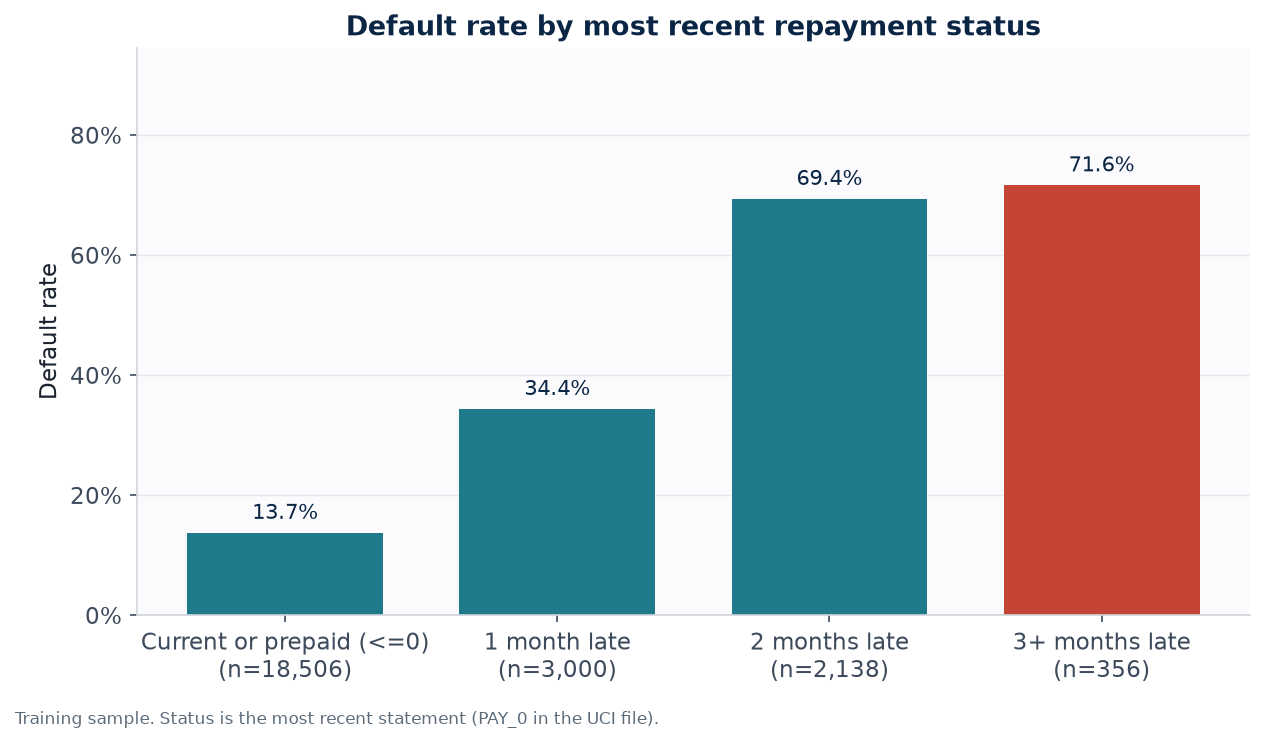

,band,accounts,default_rate
0,1 month late,3000,0.3437
1,2 months late,2138,0.6936
2,3+ months late,356,0.7163
3,Current or prepaid (<=0),18506,0.1373


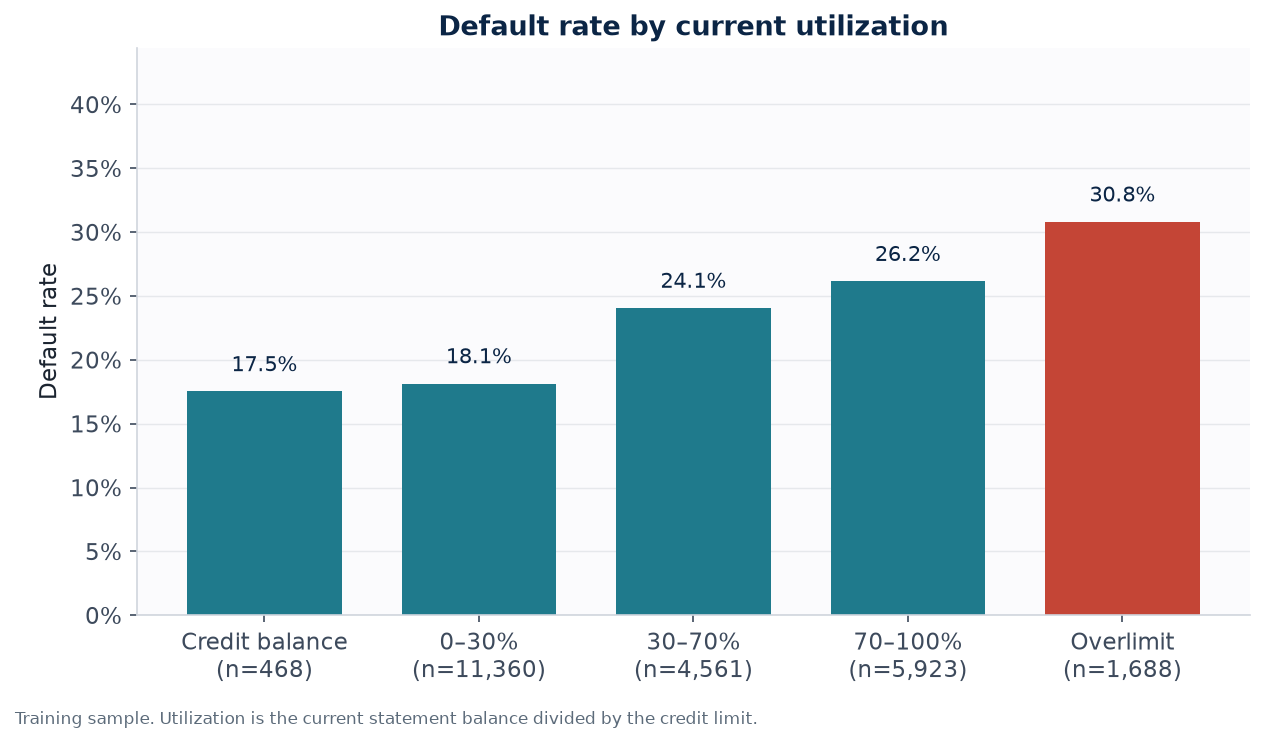

,band,accounts,default_rate
0,0–30%,11360,0.1814
1,30–70%,4561,0.2405
2,70–100%,5923,0.2615
3,Credit balance,468,0.1752
4,Overlimit,1688,0.3081


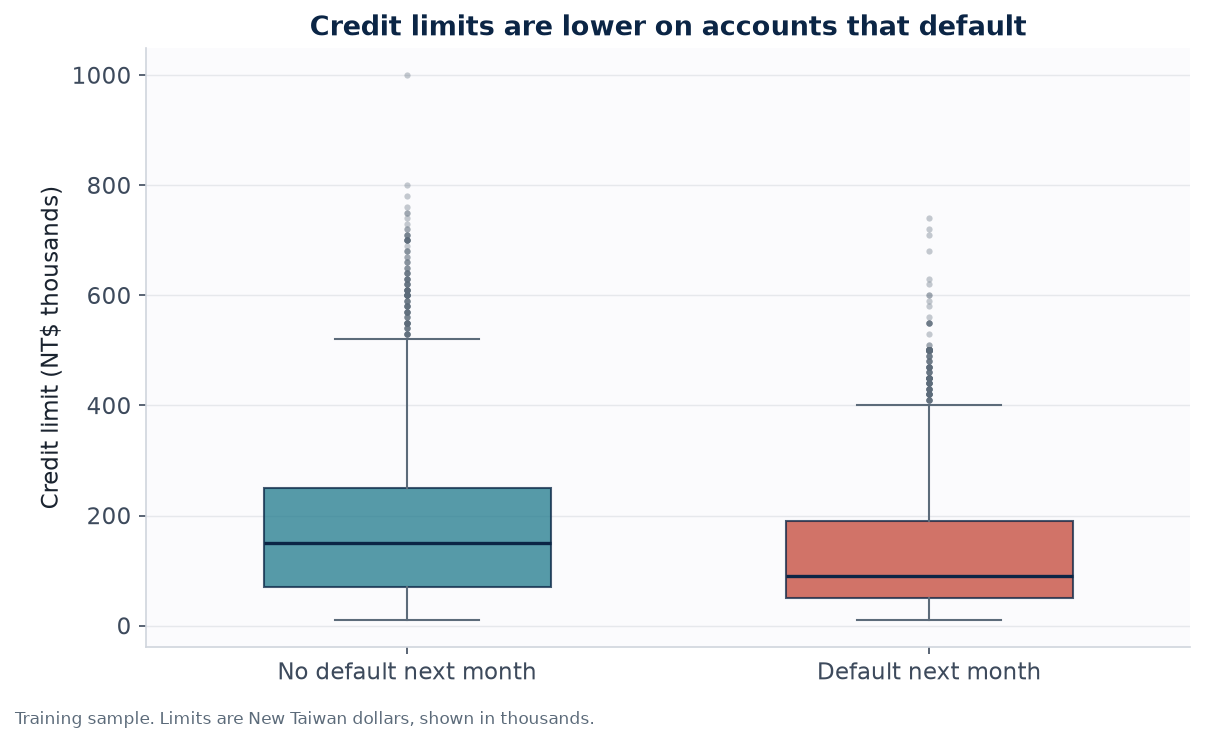

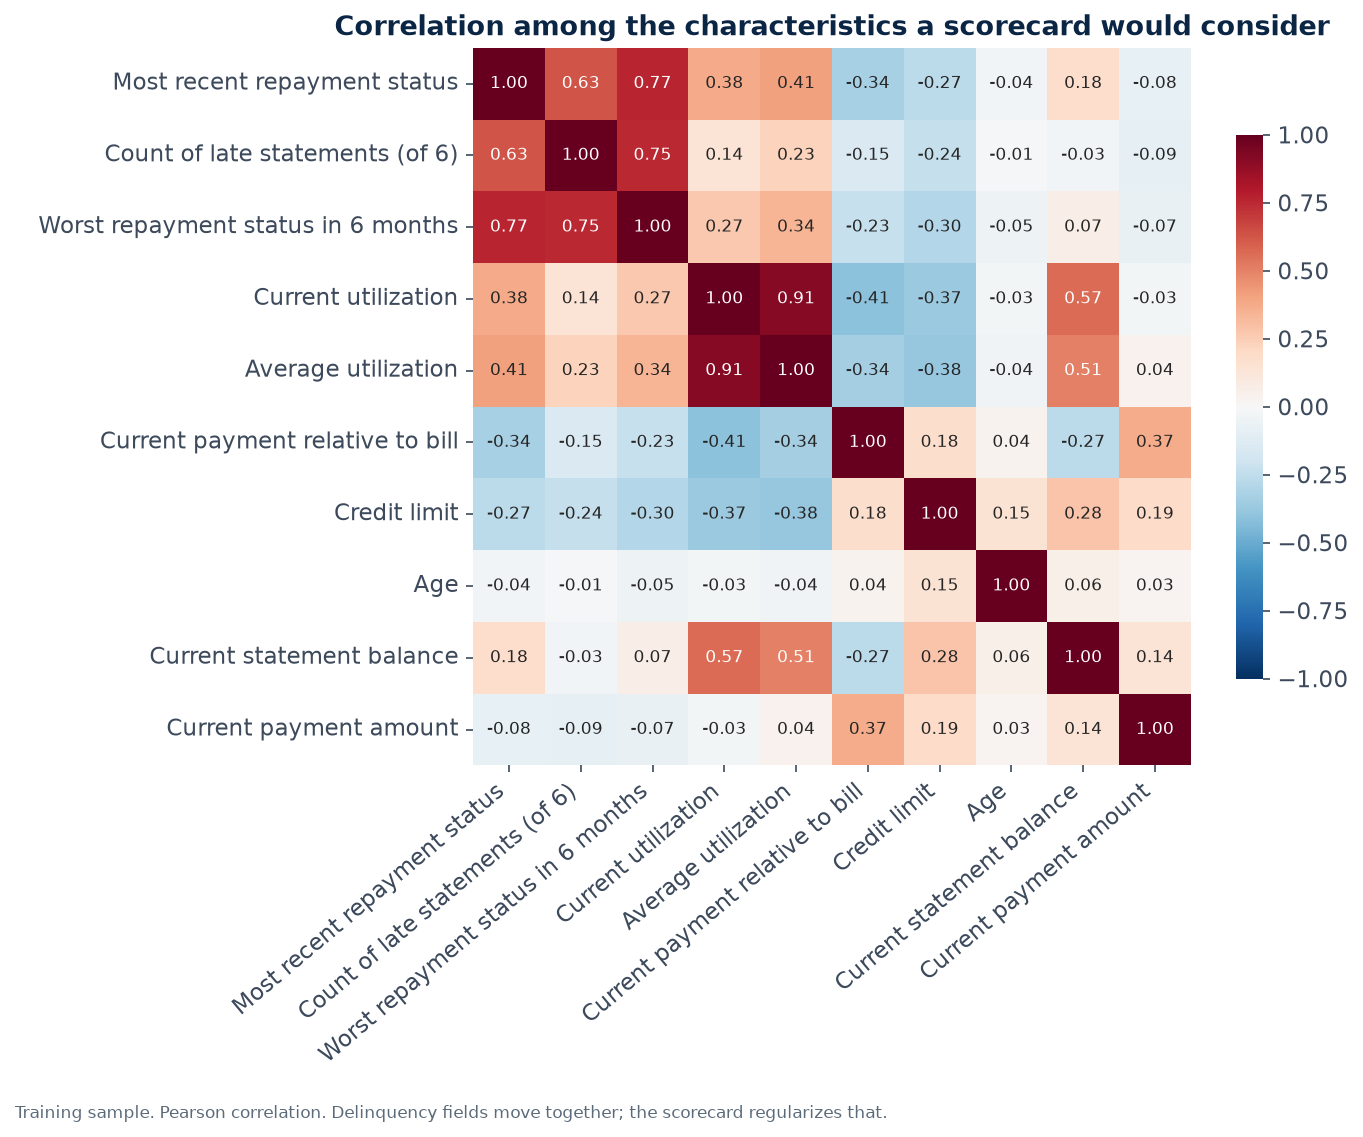

In [3]:
def show(name):
    display(Image(filename=str(root / "reports" / "figures" / name)))

show("01_default_rate_by_repayment.png")
display(pd.DataFrame(metrics["eda"]["repayment"]))
show("02_default_rate_by_utilization.png")
display(pd.DataFrame(metrics["eda"]["utilization"]))
show("03_limit_by_default.png")
show("04_correlation.png")

## 4. Scorecard evidence

Weight of evidence is ln(share of non-defaults / share of defaults), so a higher WOE bin is safer and the logistic coefficient on default should be negative. Information value under 0.02 is screened out. Nothing was. No coefficient had the wrong sign, so every characteristic stayed in.

The delinquency pair is very strong and correlated. Limit and the payment ratio are medium. Utilization, education, and age are weak. The points column is the points-to-double-odds scaling: 20 points doubles the odds of non-default.

In [4]:
display(result["iv_table"])
points = result["scorecard_table"]
display(points.loc[points["feature"].isin(["pay_1", "months_late"]), [
    "feature", "bin", "accounts", "default_rate", "woe", "points"
]])
scorecard = metrics["models"]["scorecard"]
print("Kept:", ", ".join(scorecard["kept_features"]))
print("Screened for low IV:", scorecard["screened_out_low_iv"] or "none")
print("Dropped for sign:", scorecard["dropped_wrong_sign"] or "none")
print(f"Base points: {scorecard['base_points']:.1f}")

,feature,information_value,n_bins,strength
0,pay_1,0.8722,4,very strong
1,months_late,0.8572,4,very strong
2,limit_bal,0.1712,5,medium
3,pay_ratio_1,0.1442,5,medium
4,util_1,0.0596,5,weak
5,education,0.0361,4,weak
6,age,0.0224,5,weak


,feature,bin,accounts,default_rate,woe,points
0,pay_1,Current or prepaid (<=0),18506,0.1373,0.5798,9.8032
1,pay_1,1 month late,3000,0.3437,-0.6116,-10.3416
2,pay_1,2 months late,2138,0.6936,-2.0751,-35.0884
3,pay_1,3+ months late,356,0.7163,-2.1815,-36.8876
4,months_late,0 months late,15896,0.1151,0.7808,11.5084
5,months_late,1 month late,3572,0.2996,-0.4092,-6.0311
6,months_late,2 months late,1532,0.3995,-0.8510,-12.5425
7,months_late,3+ months late,3000,0.5990,-1.6595,-24.4591


Kept: pay_1, months_late, util_1, pay_ratio_1, limit_bal, age, education
Screened for low IV: none
Dropped for sign: none
Base points: 549.8


## 5. Holdout discrimination

The repayment-status rule is the baseline a collector already has. The scorecard is the interpretable model. Boosting is the decision model because its training AUC cleared the scorecard by more than 0.005. Holdout metrics below were not used to choose it.

,model,auc,gini,ks
0,Repayment status,0.6762,0.3524,0.3553
1,Utilization only,0.5347,0.0693,0.1018
2,Scorecard,0.7396,0.4792,0.3890
3,Gradient boosting,0.7824,0.5647,0.4279


,model,weighting,cv_auc,cv_auc_std,unweighted_cv_auc,balanced_cv_auc,holdout_auc,psi
0,scorecard,unweighted,0.7576,0.0090,0.7576,0.7579,0.7396,0.0066
1,gradient_boosting,unweighted,0.7874,0.0061,0.7874,0.7872,0.7824,0.0027


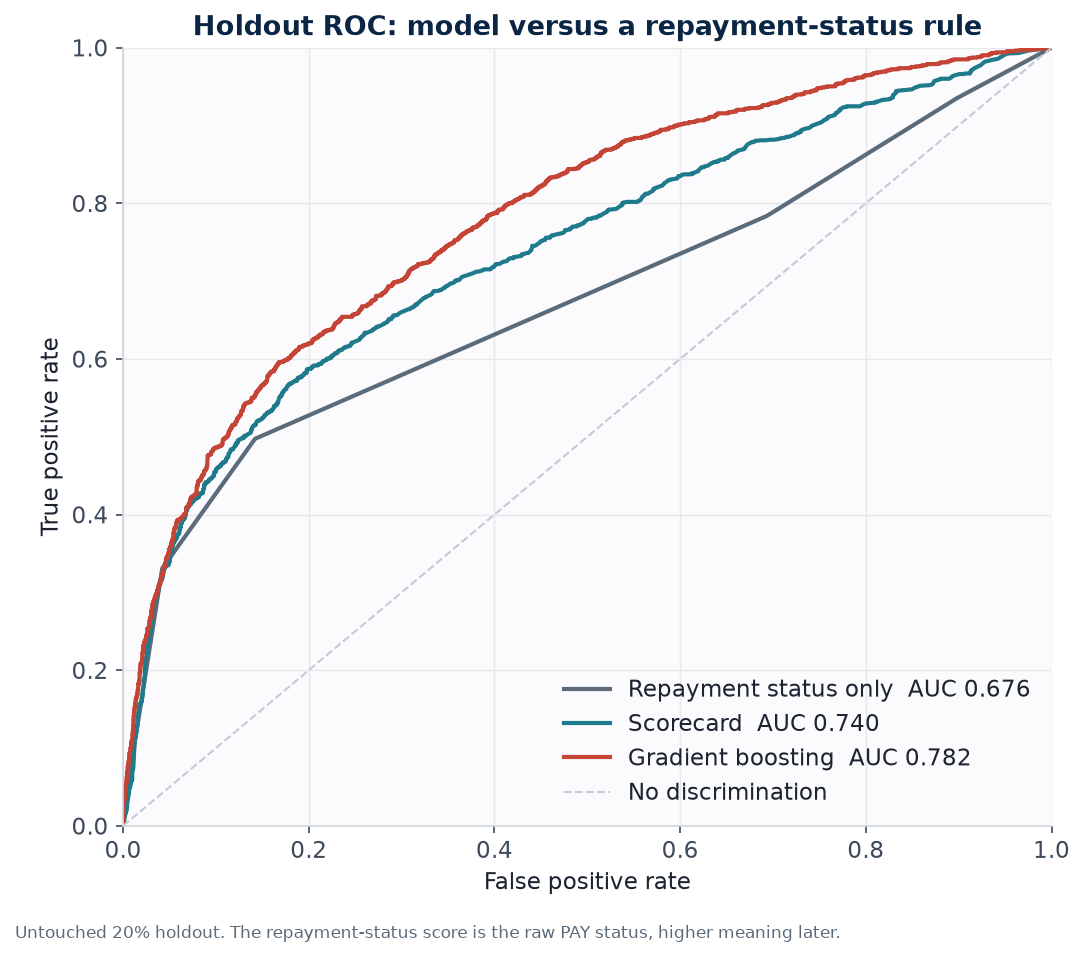

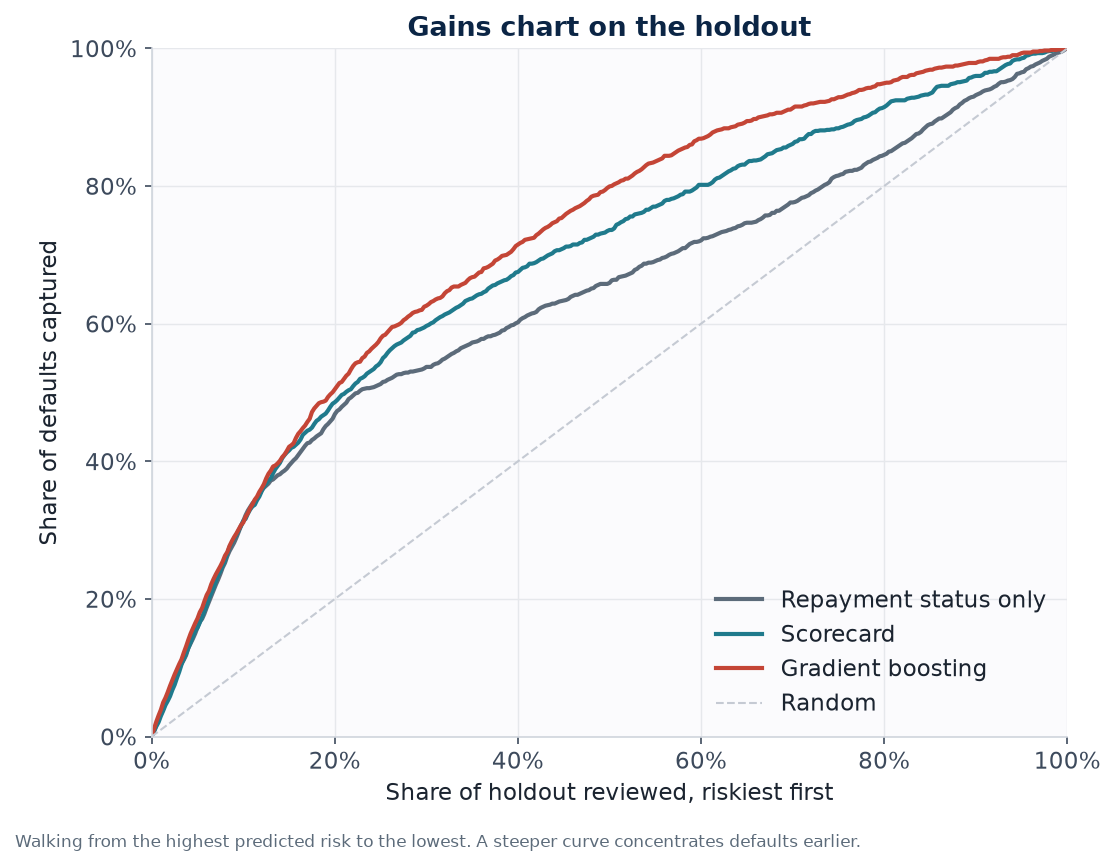

Share of defaults captured in the riskiest slice of the holdout


,capture
at_10pct,0.3112
at_20pct,0.5041
at_30pct,0.6262
baseline_at_30pct,0.5365


In [5]:
rows = []
for name, block in {
    "Repayment status": metrics["baselines"]["repayment_status"],
    "Utilization only": metrics["baselines"]["utilization"],
    "Scorecard": metrics["models"]["scorecard"],
    "Gradient boosting": metrics["models"]["gradient_boosting"],
}.items():
    rows.append(
        {
            "model": name,
            "auc": block["auc"] if "auc" in block else block["test_auc"],
            "gini": block["gini"] if "gini" in block else block["test_gini"],
            "ks": block["ks"] if "ks" in block else block["test_ks"],
        }
    )
comparison = pd.DataFrame(rows)
display(comparison)

cv = pd.DataFrame(
    [
        {
            "model": name,
            "weighting": metrics["models"][name]["weighting"],
            "cv_auc": metrics["models"][name]["cv_auc"],
            "cv_auc_std": metrics["models"][name]["cv_auc_std"],
            "unweighted_cv_auc": metrics["models"][name]["unweighted_cv_auc"],
            "balanced_cv_auc": metrics["models"][name]["balanced_cv_auc"],
            "holdout_auc": metrics["models"][name]["test_auc"],
            "psi": metrics["models"][name]["psi"],
        }
        for name in ("scorecard", "gradient_boosting")
    ]
)
display(cv)
show("05_roc_curves.png")
show("06_gains_chart.png")
print("Share of defaults captured in the riskiest slice of the holdout")
display(pd.Series(metrics["capture"]).to_frame("capture"))

## 6. Deciles and calibration

Decile 1 is the riskiest tenth. Observed default rate should step down, and mean PD should sit next to it. The constant-PD Brier score is the bar the model has to beat. ECE is the average absolute gap between outcome and predicted PD across ten equal-count bins.

,decile,accounts,defaults,observed_default_rate,mean_score,mean_calibrated_pd,share_of_defaults,share_of_non_defaults,cumulative_default_capture,cumulative_non_default_capture,ks_gap
0,1,600,413,0.6883,0.7166,0.7147,0.3112,0.0400,0.3112,0.0400,0.2712
1,2,600,256,0.4267,0.4334,0.4325,0.1929,0.0736,0.5041,0.1136,0.3905
2,3,600,162,0.2700,0.2811,0.2824,0.1221,0.0937,0.6262,0.2074,0.4189
3,4,600,118,0.1967,0.1998,0.1899,0.0889,0.1031,0.7151,0.3105,0.4046
4,5,600,112,0.1867,0.1600,0.1659,0.0844,0.1044,0.7995,0.4149,0.3846
5,6,600,92,0.1533,0.1342,0.1408,0.0693,0.1087,0.8689,0.5236,0.3452
6,7,600,59,0.0983,0.1098,0.1106,0.0445,0.1158,0.9133,0.6394,0.2739
7,8,600,48,0.0800,0.0854,0.0849,0.0362,0.1181,0.9495,0.7575,0.1920
8,9,600,39,0.0650,0.0639,0.0615,0.0294,0.1201,0.9789,0.8776,0.1013
9,10,600,28,0.0467,0.0410,0.0421,0.0211,0.1224,1.0000,1.0000,-0.0000


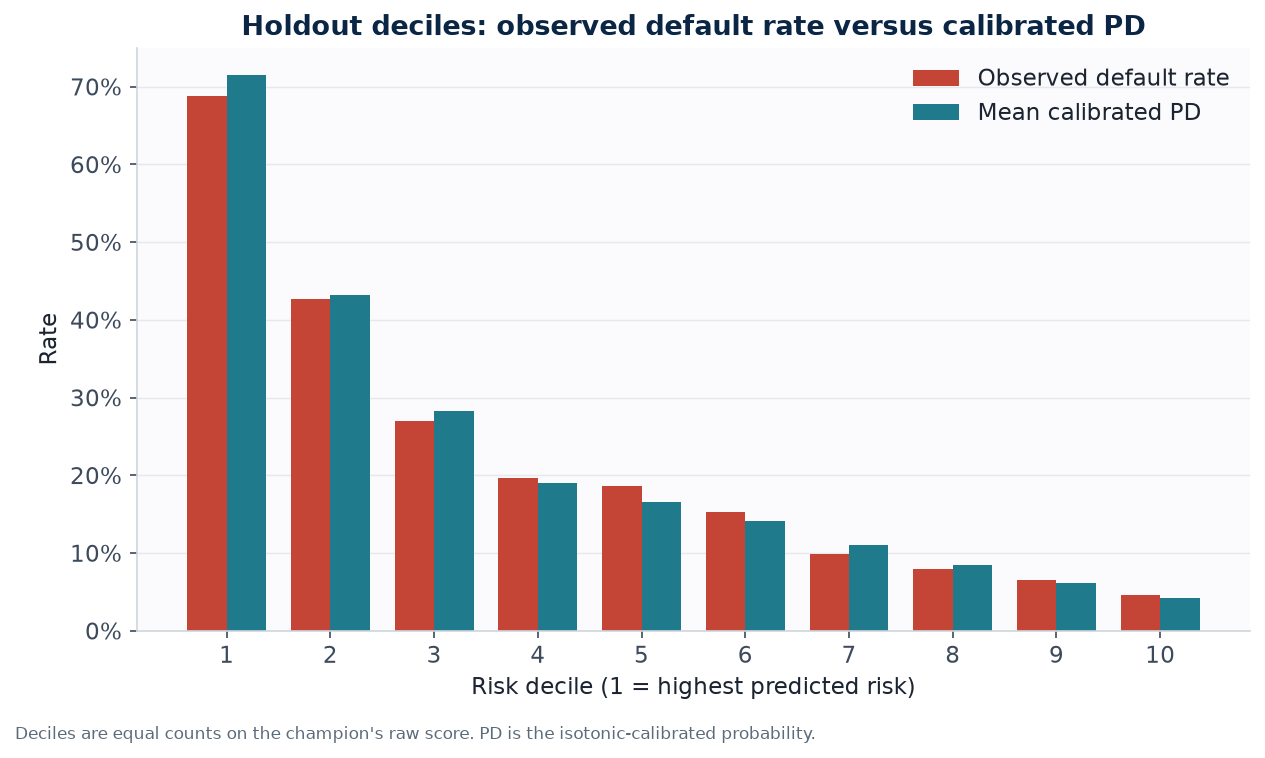

,value
brier_model_raw,0.1349
brier_model_calibrated,0.1349
brier_constant_base_rate,0.1723
ece_raw,0.0119
ece_calibrated,0.0143
holdout_mean_pd,0.2225
holdout_default_rate,0.2212


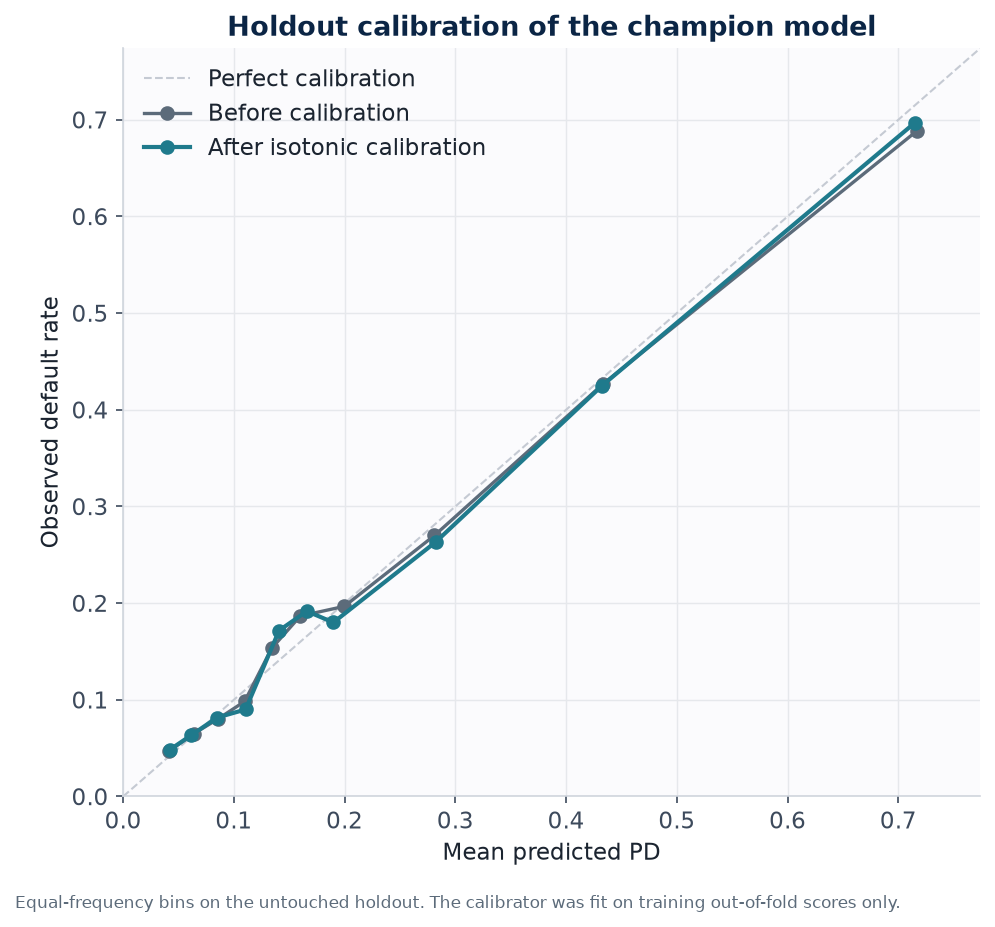

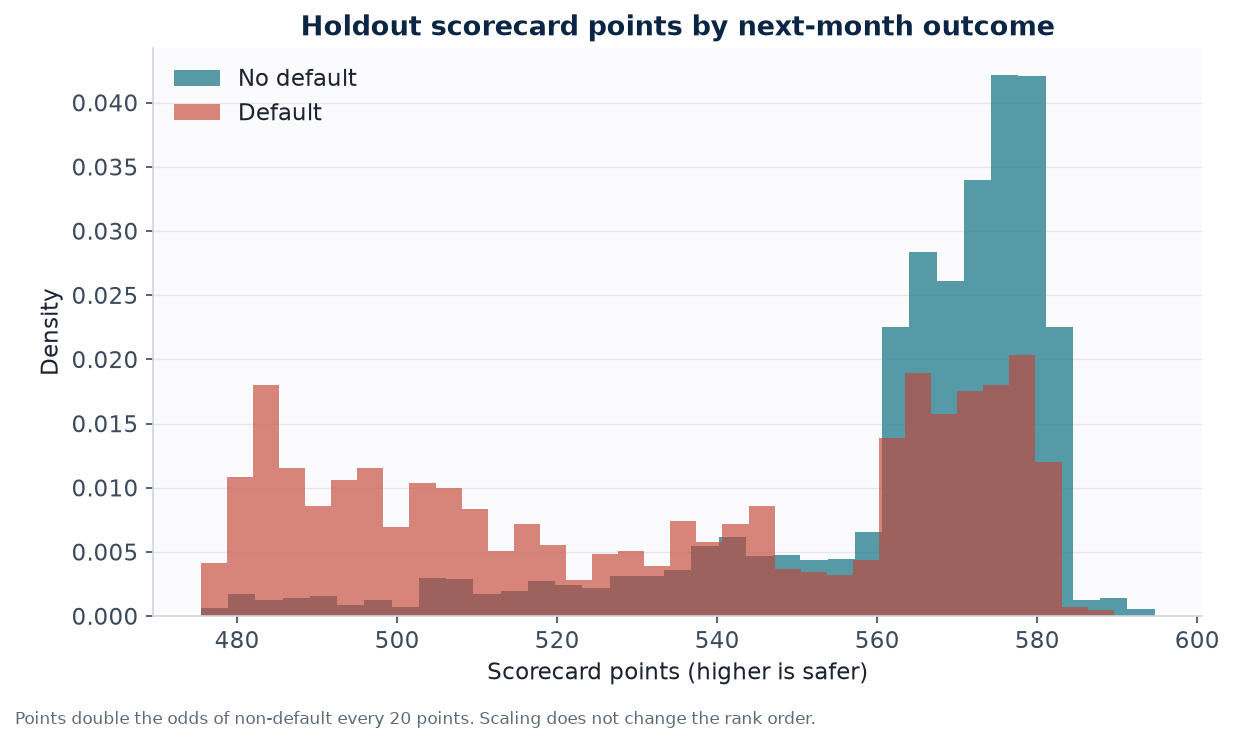

In [6]:
display(result["deciles"])
show("07_decile_rates.png")
champion = metrics["models"][metrics["champion"]]
calibration = pd.Series(
    {
        "brier_model_raw": champion["brier_raw"],
        "brier_model_calibrated": champion["brier_calibrated"],
        "brier_constant_base_rate": champion["brier_base_rate"],
        "ece_raw": champion["ece_raw"],
        "ece_calibrated": champion["ece_calibrated"],
        "holdout_mean_pd": metrics["expected_loss"]["holdout"]["mean_pd"],
        "holdout_default_rate": metrics["expected_loss"]["holdout"]["observed_default_rate"],
    }
)
display(calibration.to_frame("value"))
show("08_calibration.png")
show("09_score_distribution.png")

## 7. What the model is using

SHAP is computed on the boosting model, which is the model that ranks the book. Mean absolute SHAP is a rank of influence, not a sign. The score distribution above is the logistic scorecard on the same holdout: higher points are safer, and the two humps are mostly "has been late" versus "has not."

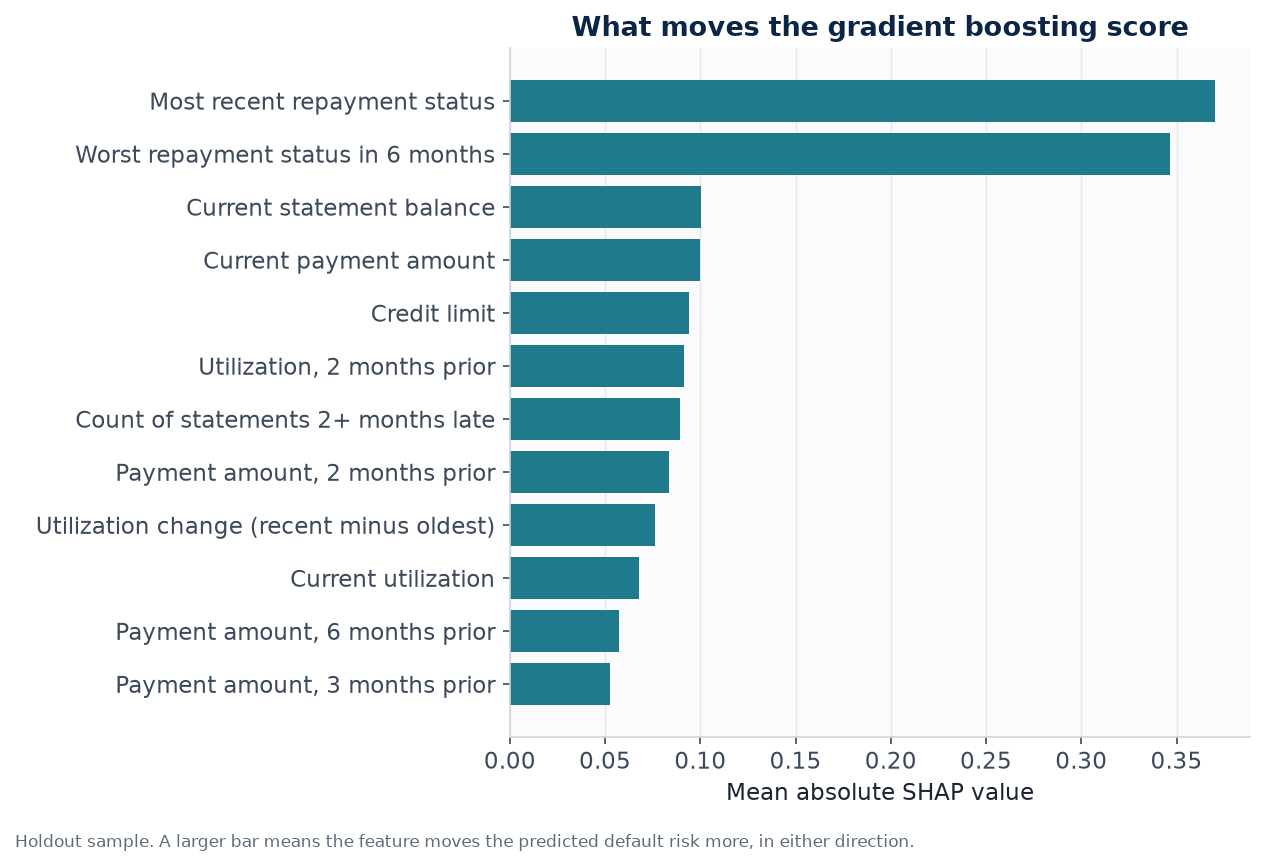

,feature,mean_abs_shap,label
0,pay_1,0.3702,Most recent repayment status
1,max_delay,0.3466,Worst repayment status in 6 months
2,bill_amt1,0.1004,Current statement balance
3,pay_amt1,0.1000,Current payment amount
4,limit_bal,0.0940,Credit limit
5,util_2,0.0914,"Utilization, 2 months prior"
6,months_severe,0.0893,Count of statements 2+ months late
7,pay_amt2,0.0833,"Payment amount, 2 months prior"
8,util_recent_minus_old,0.0763,Utilization change (recent minus oldest)
9,util_1,0.0679,Current utilization


In [7]:
show("10_shap_importance.png")
display(result["importance"].head(12))

## 8. Expected loss

EAD is the positive statement balance plus 10% of the undrawn limit. A credit balance (negative bill) contributes zero drawn exposure. EL = calibrated PD × 0.75 × EAD. The 45% LGD row is the same PD and EAD with a lower severity. Grades are equal-count fifths of the holdout.

,accounts,defaults,observed_default_rate,mean_pd,total_ead,total_expected_loss,el_rate,segment
0,4676,667,0.1426,0.1394,"306,942,725.4000","26,815,174.6316",0.0874,Current or prepaid
1,1324,660,0.4985,0.5162,"73,728,407.2000","31,646,018.7382",0.4292,Already late
2,6000,1327,0.2212,0.2225,"380,671,132.6000","58,461,193.3698",0.1536,Full holdout


,lgd,ccf,total_expected_loss,el_rate
0,0.7500,0.1000,"58,461,193.3698",0.1536
1,0.4500,0.1000,"35,076,716.0219",0.0921


,risk_grade,accounts,defaults,observed_default_rate,mean_pd,total_ead,total_expected_loss,el_rate,share_of_accounts,share_of_expected_loss
0,1,1200,67,0.0558,0.0518,"102,356,260.3000","3,867,094.8365",0.0378,0.2000,0.0661
1,2,1200,107,0.0892,0.0978,"83,061,362.4000","6,068,723.9455",0.0731,0.2000,0.1038
2,3,1200,204,0.1700,0.1534,"76,696,396.5000","8,766,150.4678",0.1143,0.2000,0.1499
3,4,1200,280,0.2333,0.2361,"50,780,736.3000","8,810,887.5028",0.1735,0.2000,0.1507
4,5,1200,669,0.5575,0.5736,"67,776,377.1000","30,948,336.6172",0.4566,0.2000,0.5294


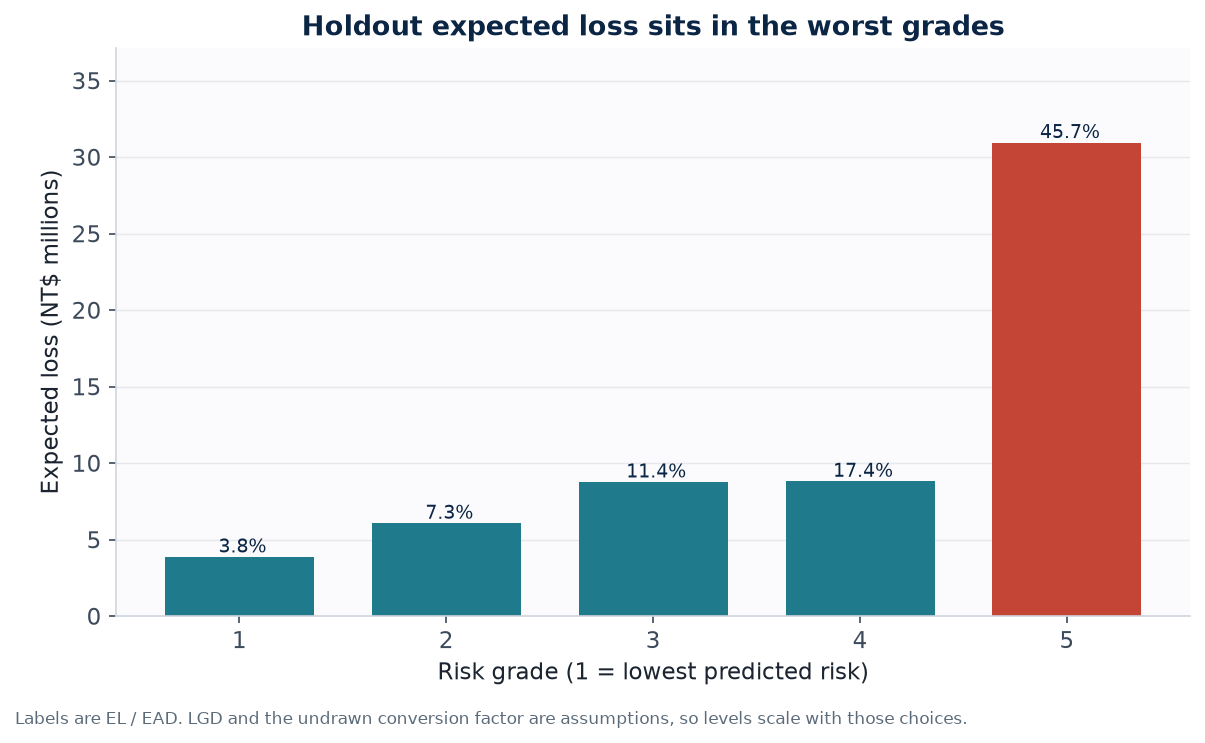

,risk_grade,accounts,avg_pd,observed_default_rate,total_ead,total_expected_loss,el_rate
0,1,1200,0.0518,0.0558,"102,356,260.0000","3,867,095.0000",0.0378
1,2,1200,0.0978,0.0892,"83,061,362.0000","6,068,724.0000",0.0731
2,3,1200,0.1534,0.1700,"76,696,397.0000","8,766,150.0000",0.1143
3,4,1200,0.2361,0.2333,"50,780,736.0000","8,810,888.0000",0.1735
4,5,1200,0.5736,0.5575,"67,776,377.0000","30,948,337.0000",0.4566


,total_expected_loss,total_ead,el_rate,highest_grade_expected_loss,share_of_el_in_highest_grade
0,"58,461,193.0000","380,671,133.0000",0.1536,"30,948,337.0000",0.5294


In [8]:
display(result["slices"])
display(result["sensitivities"])
display(result["grades"])
show("12_expected_loss_by_grade.png")
display(result["sql"]["expected_loss_by_risk_grade"])
display(result["sql"]["expected_loss_concentration"])

## 9. Cutoff

Safest accounts are accepted first. The 70% row is the illustrated policy. There is no margin in the file, so the curve is the bad-rate tradeoff and not a profit optimum. "Defaults removed" is the share of all holdout defaults that fall outside the accepted book.

,approval_rate,accounts_accepted,pd_threshold,observed_bad_rate,mean_pd,defaults_excluded_share,non_defaults_excluded_share,accepted_ead,accepted_expected_loss,accepted_el_rate
0,0.5000,3000,0.1659,0.0887,0.0880,0.7995,0.4149,"226,912,330.2000","14,320,934.3717",0.0631
1,0.6000,3600,0.1659,0.1050,0.1010,0.7151,0.3105,"262,114,019.2000","18,701,969.2497",0.0714
2,0.7000,4200,0.2295,0.1181,0.1137,0.6262,0.2074,"289,387,541.2000","22,540,895.8783",0.0779
3,0.8000,4800,0.3407,0.1371,0.1348,0.5041,0.1136,"312,894,755.5000","27,512,856.7526",0.0879
4,0.9000,5400,0.6146,0.1693,0.1679,0.3112,0.0400,"338,138,554.1000","35,830,007.2762",0.1060
5,1.0000,6000,0.8367,0.2212,0.2225,0.0000,0.0000,"380,671,132.6000","58,461,193.3698",0.1536


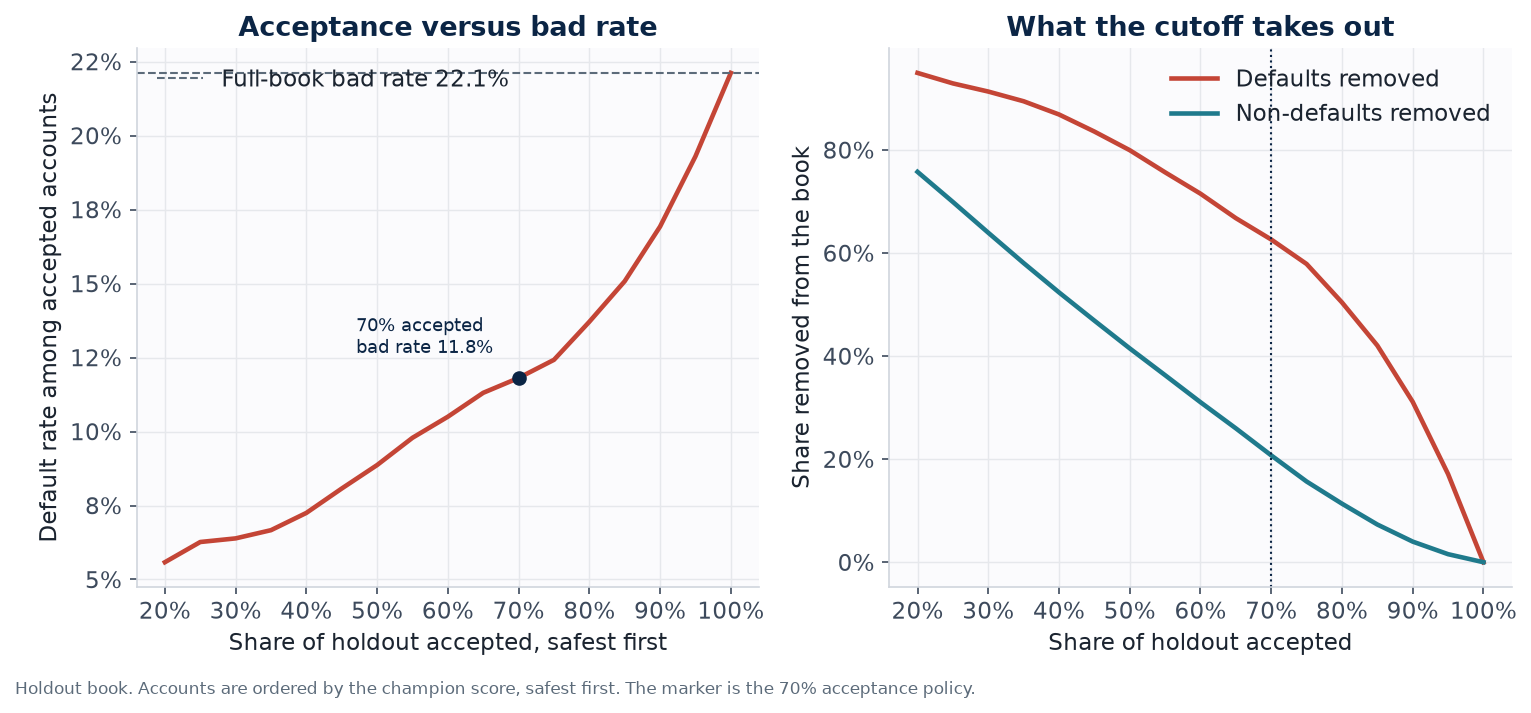

In [9]:
display(result["cutoff"])
show("11_cutoff_tradeoff.png")

## 10. Monitoring and adverse-action reasons

Sex and marital status are not inputs. The tables still use one global cutoff, so a proxy through limit or delinquency would show up here. Education and age are inputs. The "Other" education bin is small and includes undocumented codes; read that approval rate with the count beside it.

SHAP reasons belong to the boosting decision. Scorecard reasons are the points shortfall versus the training-average account. They are shown together so a reviewer can see whether the transparent model agrees.

sex  lowest/highest approval  0.954


,group,accounts,approval_rate,bad_rate_if_approved,observed_default_rate,mean_pd,approval_vs_highest_group
0,Female,3598,0.7132,0.1118,0.2129,0.2172,1.0000
1,Male,2402,0.6803,0.1279,0.2336,0.2306,0.9539


education  lowest/highest approval  0.703


,group,accounts,approval_rate,bad_rate_if_approved,observed_default_rate,mean_pd,approval_vs_highest_group
0,Graduate school,2130,0.7502,0.0995,0.1901,0.1930,0.7990
1,High school,1014,0.6598,0.1540,0.2574,0.2461,0.7026
2,Other,82,0.9390,0.0519,0.0610,0.0808,1.0000
3,University,2774,0.6691,0.1239,0.2365,0.2407,0.7125


marriage  lowest/highest approval  0.982


,group,accounts,approval_rate,bad_rate_if_approved,observed_default_rate,mean_pd,approval_vs_highest_group
0,Married,2767,0.6935,0.1277,0.2414,0.2250,0.9826
1,Other,75,0.6933,0.1154,0.1600,0.2319,0.9823
2,Single,3158,0.7058,0.1099,0.2049,0.2202,1.0000


age  lowest/highest approval  0.81


,group,accounts,approval_rate,bad_rate_if_approved,observed_default_rate,mean_pd,approval_vs_highest_group
0,21–25,767,0.5997,0.1261,0.2555,0.2753,0.8101
1,26–35,2492,0.7404,0.1068,0.1966,0.2000,1.0000
2,36–45,1775,0.7059,0.1261,0.2237,0.2194,0.9535
3,46–55,788,0.6688,0.1271,0.2513,0.2430,0.9033
4,56+,178,0.6461,0.1391,0.2584,0.2521,0.8726


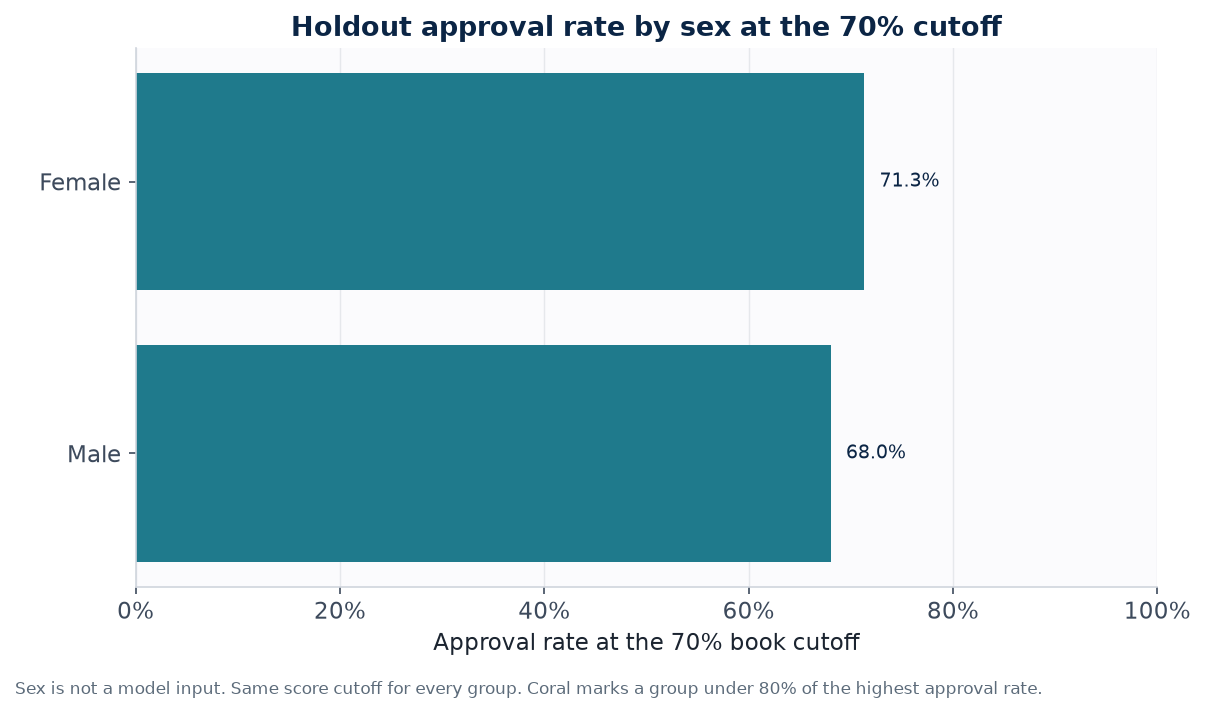

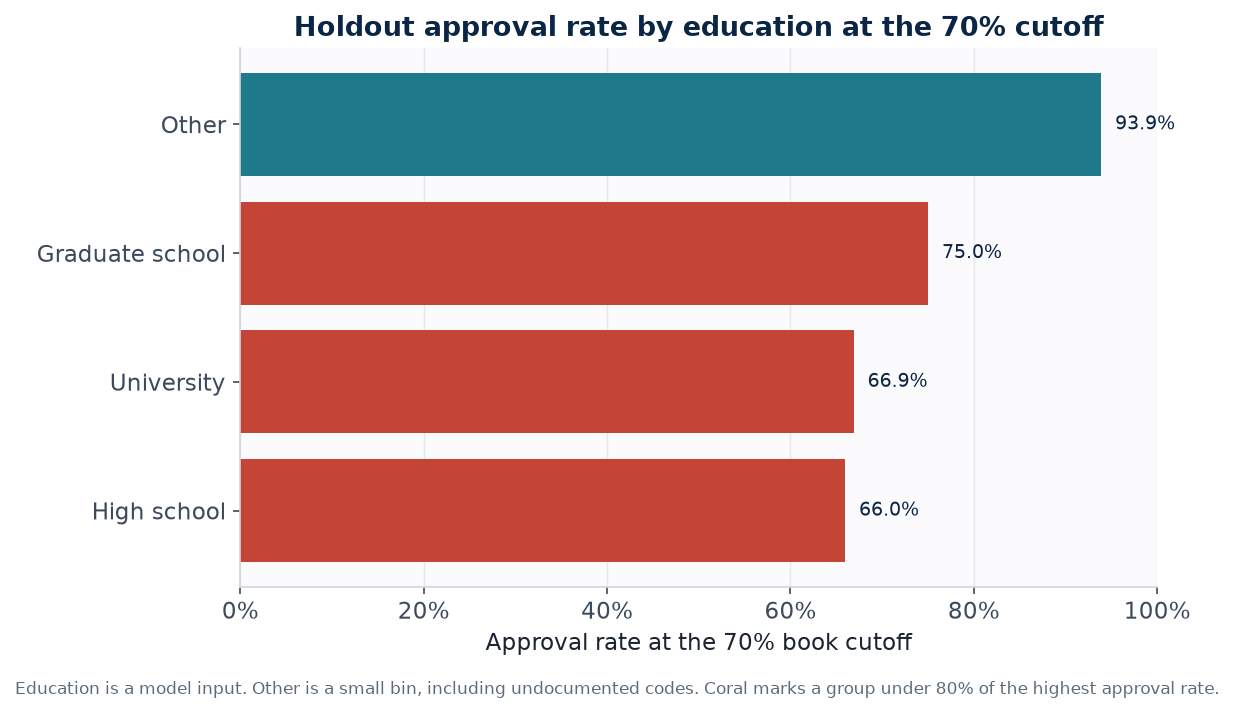


Account 12970  marginal decline  PD 23.0%  scorecard 550 points  status 0  util 0.98  limit 50,000
  Scorecard:
    - Late-payment history is 1 month late  (shortfall 8.9 points)
    - Credit limit is NT$10,000–50,000  (shortfall 6.7 points)
    - Current utilization is 70–100%  (shortfall 0.5 points)
  SHAP:
    - Worst repayment status in 6 months (2) increased predicted default risk
    - Utilization, 2 months prior (0.98) increased predicted default risk
    - Credit limit (50,000) increased predicted default risk
    - Current utilization (0.98) increased predicted default risk

Account 15661  marginal decline  PD 23.0%  scorecard 537 points  status 1  util -0.00  limit 200,000
  Scorecard:
    - Recent repayment status is 1 month late  (shortfall 12.9 points)
    - Late-payment history is 1 month late  (shortfall 8.9 points)
    - Education category is University  (shortfall 1.1 points)
    - Recent payment pattern is No positive statement balance  (shortfall 0.3 points)
  SHAP:

In [10]:
for name, table in result["fairness"].items():
    print(name, " lowest/highest approval ", round(metrics["fairness"]["ratios_vs_highest_group"][name], 3))
    display(table)

show("13_approval_by_sex.png")
show("14_approval_by_education.png")

for example in result["examples"]:
    print(
        f"\nAccount {example['account_id']}  {example['position']}  "
        f"PD {example['calibrated_pd']:.1%}  scorecard {example['scorecard_points']:.0f} points  "
        f"status {example['pay_1']}  util {example['util_1']:.2f}  limit {example['limit_bal']:,.0f}"
    )
    print("  Scorecard:")
    for reason in example["scorecard_reasons"]:
        print(f"    - {reason['reason']}  (shortfall {reason['shortfall']:.1f} points)")
    print("  SHAP:")
    for reason in example["shap_reasons"]:
        print(f"    - {reason['reason']}")

## 11. SQL

The queries in `sql/portfolio_queries.sql` run in SQLite against the cleaned book (`accounts`) and the scored holdout (`scored_book`). The segment cut below is the analyst version of the chart in section 3: still-current accounts with high utilization, versus accounts already late.

In [11]:
display(result["sql"]["behavior_segments"])
display(result["sql"]["default_rate_by_age_band"])
display(result["sql"]["delinquent_balance_watchlist"].head(8))

,segment,accounts,default_rate,avg_utilization,avg_balance
0,"Current, utilization under 70%",16216,0.1302,0.1823,"30,038.0000"
1,Current but highly utilized,6966,0.1572,0.9412,"108,013.0000"
2,1 month late,3688,0.3395,0.3229,"27,153.0000"
3,2+ months late,3130,0.6955,0.6421,"62,951.0000"


,age_band,accounts,defaults,default_rate,avg_limit
0,21-25,3871,1032,0.2666,"73,764.0000"
1,26-35,12938,2565,0.1983,"179,269.0000"
2,36-45,8522,1861,0.2184,"191,441.0000"
3,46-55,3825,954,0.2494,"169,161.0000"
4,56+,844,224,0.2654,"167,192.0000"


,account_id,limit_bal,bill_amt1,util_1,pay_1,months_late,default_flag
0,27499,"500,000.0000","613,860.0000",1.2280,2,1,1
1,28625,"340,000.0000","589,654.0000",1.7340,5,5,1
2,5925,"340,000.0000","581,775.0000",1.7110,4,3,1
3,10769,"500,000.0000","564,757.0000",1.1300,2,1,1
4,23378,"550,000.0000","548,551.0000",0.9970,2,1,1
5,20893,"550,000.0000","539,092.0000",0.9800,2,5,0
6,4324,"500,000.0000","533,142.0000",1.0660,2,3,0
7,26087,"320,000.0000","520,651.0000",1.6270,2,1,1


## 12. What this does not support

The holdout is a random slice of one 2005 cross-section, so it is not an out-of-time test. LGD and the undrawn factor are assumptions; the EL rate moves in proportion to LGD. Statement history would be absent for a new applicant, so this specification is a behavioral PD. Age and education are weak and would go through a Regulation B review before either was used in a U.S. decision. The reason-code examples are not an adverse-action notice.

Headline numbers for this seed are also written to `reports/metrics.json` and `reports/CreditRiskPortfolio.xlsx`.